# ML Week 2 - Exploratory Data Analysis (EDA)
##### Let's attack some heavy-duty archaeological data! Note that there are a huge number of different steps you may need to do in the data "wrangling" process. They will vary imensely from one dataset to another.

##### Note: With bigger files some of these cells can take a few minutes to execute. Be patient ;)

### Datset
We will be using a Zooarchaeology Dataset from several Epipaleolithic - Chalcolithic sites in Anatolia.

The associated publication is:

Arbuckle et al. 2017, https://doi.org/10.34894/WT8CSG

You can download the dataset here (159 Mb):

https://dataverse.nl/dataset.xhtml?persistentId=doi:10.34894/WT8CSG

## Importing Common Packages
##### These are the packages we will be using for this exercise

In [ ]:
%pip install seaborn

In [3]:
import pandas as pd
import seaborn as sns

## Import Data and Examine DataFrame
##### Let's look at the first few rows and see what we have

In [4]:
# Let's read in our data
filepath = "./"  # This can help if the file is in a different folder. Here we just use "./" which means "the file is in this folder"
filename = "EOL-CDC Primary Zooarchaeology data.csv"

df_raw = pd.read_csv(filepath + filename)

df_raw.head()

C:\Users\re72fam\AppData\Local\Temp\ipykernel_30608\819371253.py:5: DtypeWarning: Columns (0: Context (5), 1: Context (6), 2: Context (7), 3: Context (8), 4: Context (9), 5: Has physiological sex determination [URI], 6: Has physiological sex determination [Label], 7: Has physiological sex determination [Source]) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(filepath + filename)


,URI,Label,Project,Project URI,Item Category,Last Updated,Authorship,Latitude (WGS-84),Longitude (WGS-84),Geospatial note,...,Has Biological Taxonomy [Source],Has fusion character [Proximal URI],Has fusion character [Proximal Label],Has fusion character [Proximal Source],Has fusion character [Distal URI],Has fusion character [Distal Label],Has fusion character [Distal Source],Has physiological sex determination [URI],Has physiological sex determination [Label],Has physiological sex determination [Source]
0,http://opencontext.org/subjects/CC80A04F-455E-...,Bone 9290,Çatalhöyük Area TP Zooarchaeology,http://opencontext.org/projects/02594C48-7497-...,Animal Bone,2014-07-23,Arek Marciniak; Kamilla Pawlowska,37.668196,32.827191,Best available location data,...,Sheep-size (medium dog to medium sheep),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,http://opencontext.org/subjects/208259AB-BAC9-...,Bone 9291,Çatalhöyük Area TP Zooarchaeology,http://opencontext.org/projects/02594C48-7497-...,Animal Bone,2014-07-23,Arek Marciniak; Kamilla Pawlowska,37.668196,32.827191,Best available location data,...,Sheep-size (medium dog to medium sheep),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,http://opencontext.org/subjects/34C7E413-4807-...,Bone 9292,Çatalhöyük Area TP Zooarchaeology,http://opencontext.org/projects/02594C48-7497-...,Animal Bone,2014-07-22,Arek Marciniak; Kamilla Pawlowska,37.668196,32.827191,Best available location data,...,Sheep-size (medium dog to medium sheep),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,http://opencontext.org/subjects/43E9607D-106A-...,Bone 9293,Çatalhöyük Area TP Zooarchaeology,http://opencontext.org/projects/02594C48-7497-...,Animal Bone,2014-07-22,Arek Marciniak; Kamilla Pawlowska,37.668196,32.827191,Best available location data,...,Sheep-size (medium dog to medium sheep),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,http://opencontext.org/subjects/A61DE94D-CDC1-...,Bone 9294,Çatalhöyük Area TP Zooarchaeology,http://opencontext.org/projects/02594C48-7497-...,Animal Bone,2014-07-23,Arek Marciniak; Kamilla Pawlowska,37.668196,32.827191,Best available location data,...,Sheep-size (medium dog to medium sheep),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Taking a look at the shape and column names

In [5]:
df_raw.shape

(239320, 37)

In [3]:
# Let's see our columns
columns = df_raw.columns
for i in range(len(columns)):
    print(str(i) + ' ' + columns[i])

0 URI
1 Label
2 Project
3 Project URI
4 Item Category
5 Last Updated
6 Authorship
7 Latitude (WGS-84)
8 Longitude (WGS-84)
9 Geospatial note
10 Early Date (BCE/CE)
11 Late Date (BCE/CE)
12 Context URI
13 Context (1)
14 Context (2)
15 Context (3)
16 Context (4)
17 Context (5)
18 Context (6)
19 Context (7)
20 Context (8)
21 Context (9)
22 Has anatomical identification [URI]
23 Has anatomical identification [Label]
24 Has anatomical identification [Source]
25 Has Biological Taxonomy [URI]
26 Has Biological Taxonomy [Label]
27 Has Biological Taxonomy [Source]
28 Has fusion character [Proximal URI]
29 Has fusion character [Proximal Label]
30 Has fusion character [Proximal Source]
31 Has fusion character [Distal URI]
32 Has fusion character [Distal Label]
33 Has fusion character [Distal Source]
34 Has physiological sex determination [URI]
35 Has physiological sex determination [Label]
36 Has physiological sex determination [Source]


## Dropping columns we don't need

In [ ]:
# We can drop many of these! The first 4 aren't useful (it turns out "Context (2)" contains the same info as "Project"),
# and also anything to do with "URI" (this is just a hyperlink)

columns_to_drop = [df_raw.columns[i] for i in [0,1,2,3,5,6,9,12,22,25,28,31,34]]
df_raw = df_raw.drop(columns=columns_to_drop)

In [7]:
# Let's now look at the unique items for the remaining columns

for column in df_raw.columns:
    print('-------')
    print(column)
    print("Set size: " + str(len(df_raw[column].unique())))
    print(df_raw[column].unique())

-------
Item Category
Set size: 1
<ArrowStringArray>
['Animal Bone']
Length: 1, dtype: str
-------
Latitude (WGS-84)
Set size: 15
[37.668196   37.84779    37.666389   37.6675     37.33000183 37.077589
 40.267036   37.08335    38.46       37.929167   37.759171   37.35
 40.468303   37.493962   37.49432   ]
-------
Longitude (WGS-84)
Set size: 15
[32.827191   34.611821   32.8225     32.828333   37.04399872 30.5708
 29.602058   30.579436   27.35       27.359444   31.681153   31.933333
 29.309099   33.016928   33.018551  ]
-------
Early Date (BCE/CE)
Set size: 23
[ -6200  -5900  -6100  -7000  -6500  -7400  -7200 -17850 -11900 -12500
 -17840  -6000  -7040  -6750  -7500  -5500  -5600  -5450  -5700  -5800
  -2400  -2700  -6700]
-------
Late Date (BCE/CE)
Set size: 19
[ -6000  -5500  -5800  -5900  -5600  -6500  -6200  -7000 -17050 -11700
 -12100 -10950  -5660  -5700  -6250  -5400  -2000  -2400  -7500]
-------
Context (1)
Set size: 1
<ArrowStringArray>
['Turkey']
Length: 1, dtype: str
-------
Co

In [8]:
# 'Item Category is always just "Animal Bone", Context (1) is always "Turkey", and Contexts 6,7,8 also don'T seem especially helpful

df_raw = df_raw.drop(columns=['Item Category', 'Context (1)', 'Context (6)', 'Context (7)', 'Context (8)'])

In [ ]:
# We can see how many empty entries there are per column

df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 239320 entries, 0 to 239319
Data columns (total 19 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   Latitude (WGS-84)                             239320 non-null  float64
 1   Longitude (WGS-84)                            239320 non-null  float64
 2   Early Date (BCE/CE)                           239320 non-null  int64  
 3   Late Date (BCE/CE)                            239320 non-null  int64  
 4   Context (2)                                   239320 non-null  str    
 5   Context (3)                                   239320 non-null  str    
 6   Context (4)                                   226938 non-null  str    
 7   Context (5)                                   157296 non-null  str    
 8   Context (9)                                   1548 non-null    str    
 9   Has anatomical identification [Label]         235974 non-nu

In [12]:
# It may be more useful to see what percentage of the columns are empty (NaN values) using the "isna" method

length = len(df_raw)

for column in df_raw.columns:
    percent_NaN = df_raw[column].isna().sum()/length*100
    print('-------')
    print(column)
    print(percent_NaN)

-------
Latitude (WGS-84)
0.0
-------
Longitude (WGS-84)
0.0
-------
Early Date (BCE/CE)
0.0
-------
Late Date (BCE/CE)
0.0
-------
Context (2)
0.0
-------
Context (3)
0.0
-------
Context (4)
5.173825839879659
-------
Context (5)
34.273775697810464
-------
Context (9)
99.35316730737088
-------
Has anatomical identification [Label]
1.3981280294166807
-------
Has anatomical identification [Source]
0.014206919605549057
-------
Has Biological Taxonomy [Label]
2.18076215945178
-------
Has Biological Taxonomy [Source]
0.004596356342971754
-------
Has fusion character [Proximal Label]
90.05097777034933
-------
Has fusion character [Proximal Source]
90.05097777034933
-------
Has fusion character [Distal Label]
89.79191041283637
-------
Has fusion character [Distal Source]
89.79191041283637
-------
Has physiological sex determination [Label]
99.48771519304697
-------
Has physiological sex determination [Source]
85.64683269262912


In [13]:
df_raw.shape

(239320, 19)

In [ ]:
# THe last 6 elements are almost entirely NaN.
# Note that these may be important for specific applications, but as we are doing general EDA lets drop them

columns = df_raw.columns
columns_to_keep = list(columns)[0:-6]

df_raw = df_raw[columns_to_keep]

In [ ]:
# So is "Context (9)"

df_raw = df_raw.drop(columns=["Context (9)"])

In [16]:
# Now we're getting somewhere! We have 12 remainng columns that seem like they could actually be useful.

df_raw.head()

,Latitude (WGS-84),Longitude (WGS-84),Early Date (BCE/CE),Late Date (BCE/CE),Context (2),Context (3),Context (4),Context (5),Has anatomical identification [Label],Has anatomical identification [Source],Has Biological Taxonomy [Label],Has Biological Taxonomy [Source]
0,37.668196,32.827191,-6200,-6000,Çatalhöyük,Mound East,Area TP,Unit 10902,bone,Long bone,Mammalia,Sheep-size (medium dog to medium sheep)
1,37.668196,32.827191,-6200,-6000,Çatalhöyük,Mound East,Area TP,Unit 10902,bone,Long bone,Mammalia,Sheep-size (medium dog to medium sheep)
2,37.668196,32.827191,-6200,-6000,Çatalhöyük,Mound East,Area TP,Unit 10902,bone,Long bone,Mammalia,Sheep-size (medium dog to medium sheep)
3,37.668196,32.827191,-6200,-6000,Çatalhöyük,Mound East,Area TP,Unit 10902,bone,Long bone,Mammalia,Sheep-size (medium dog to medium sheep)
4,37.668196,32.827191,-6200,-6000,Çatalhöyük,Mound East,Area TP,Unit 10902,bone,Long bone,Mammalia,Sheep-size (medium dog to medium sheep)


## Engineering a New Column
Now that we've removed a lot of the useless columns, let's zoom in on the interesting ones

In [ ]:
# How about we combine the "Early Date" and "Late Date" columns into an average date column (Called simply "Date")
# We can then drop the old columns
# Note that going from a date range to a simple average is a bit sketchy in archaeology, but remember this is just a first exploration

df_raw['Date'] = df_raw[['Early Date (BCE/CE)','Late Date (BCE/CE)']].mean(axis=1)
df_raw = df_raw.drop(columns=['Early Date (BCE/CE)','Late Date (BCE/CE)'])

In [ ]:
# Let's study which animals the bones came from.
# Before doing this it may be useful to rename the "Has Biological Taxonomy [Label]" to "Animal" (that's a bit shorter to type)

df_raw = df_raw.rename(columns={'Has Biological Taxonomy [Label]':'Animal'})

In [19]:
# Let's see how many bones have been found for different animals (or genuses)

from collections import Counter
Counter(df_raw['Animal'].tolist())

Counter({'Mammalia': 100604,
         'Sheep/goat': 58941,
         'Ovis': 11194,
         'Artiodactyla': 10281,
         'Bos taurus Linnaeus, 1758': 8206,
         'Bos': 7941,
         'Sus scrofa domesticus': 7599,
         nan: 5219,
         'Equidae': 3107,
         'Mytilus galloprovincialis': 2428,
         'Dama dama (Linnaeus, 1758)': 2337,
         'Capra': 2138,
         'Ovis aries Linnaeus, 1758': 2135,
         'Capra hircus Linnaeus, 1758': 2116,
         'Cervidae': 1583,
         'Ovis orientalis': 1531,
         'Sus scrofa': 1340,
         'Homo sapiens Linnaeus, 1758': 1072,
         'dog': 849,
         'Sus': 831,
         'Unio': 799,
         'Aves': 700,
         'Capra aegagrus': 629,
         'Cervus elaphus Linnaeus, 1758': 366,
         'Vulpes': 350,
         'Capreolus': 344,
         'Carnivora': 311,
         'Lepus': 293,
         'Bos primigenius': 290,
         'Vulpes vulpes (Linnaeus, 1758)': 252,
         'Canidae': 240,
         'Cerastoderma

## Let's Study Cows!
Why not look at the "Bos" bones (related to cows)

In [20]:
# We notice there are some duplicate labels - let's replace them with simply 'Bos'

df_raw.loc[df_raw['Animal'] == 'Bos taurus Linnaeus, 1758', 'Animal'] = 'Bos'
df_raw.loc[df_raw['Animal'] == 'Bos primigenius', 'Animal'] = 'Bos'

In [21]:
# Now if we check we see all the Bos have been combined

Counter(df_raw['Animal'].tolist())

Counter({'Mammalia': 100604,
         'Sheep/goat': 58941,
         'Bos': 16437,
         'Ovis': 11194,
         'Artiodactyla': 10281,
         'Sus scrofa domesticus': 7599,
         nan: 5219,
         'Equidae': 3107,
         'Mytilus galloprovincialis': 2428,
         'Dama dama (Linnaeus, 1758)': 2337,
         'Capra': 2138,
         'Ovis aries Linnaeus, 1758': 2135,
         'Capra hircus Linnaeus, 1758': 2116,
         'Cervidae': 1583,
         'Ovis orientalis': 1531,
         'Sus scrofa': 1340,
         'Homo sapiens Linnaeus, 1758': 1072,
         'dog': 849,
         'Sus': 831,
         'Unio': 799,
         'Aves': 700,
         'Capra aegagrus': 629,
         'Cervus elaphus Linnaeus, 1758': 366,
         'Vulpes': 350,
         'Capreolus': 344,
         'Carnivora': 311,
         'Lepus': 293,
         'Vulpes vulpes (Linnaeus, 1758)': 252,
         'Canidae': 240,
         'Cerastoderma edule (Linnaeus, 1758)': 216,
         'Equidae; Equus': 210,
         'Vul

## Studying the date spread

In [22]:
# Let's make a dataframe for our cows
# We can also see the different dates that the bones were attributed to

df_cow = df_raw[df_raw['Animal'] == 'Bos']
df_cow = df_cow.drop(columns=['Animal'])
df_cow['Date'].unique()

array([ -6100.,  -5850.,  -6000.,  -5750.,  -6750.,  -6350.,  -6700.,
        -7200.,  -6800.,  -7100., -17450.,  -6250.,  -5830.,  -6370.,
        -6500.,  -5800.,  -5450.,  -5500.,  -5650.,  -5425.,  -5900.,
        -2550.,  -2200., -10000.])

(-8000.0, -4000.0)

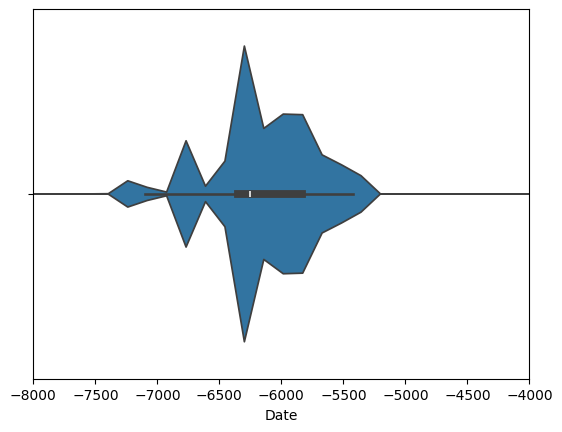

In [23]:
# A violin plot is a nice way of seeing where most cow bones have been found
ax = sns.violinplot(x=df_cow["Date"])
ax.set_xlim(-8000,-4000)

## Correlating Dates and location
We can now try to combine different columns for more interesting insights

In [24]:
# Let's try to combine the dates and the locations
# To do this, let's first simplify the names of the latitude and logitude columns

df_cow = df_cow.rename(columns={'Latitude (WGS-84)':'Lat', 'Longitude (WGS-84)':'Lon'})

In [34]:
# Context (2) is the region the bones were found.
# Let's make a new dataframe that contains the latitude, longitude, and mean date for the bones found (and also the count)

final_df = df_cow.groupby('Context (2)').agg({'Lat':'mean','Lon':'mean','Date':['mean','count']})
final_df

Lat        Lon          Date      
                     mean       mean          mean count
Context (2)                                             
Barcın Höyük    40.267036  29.602058  -6250.000000  1277
Domuztepe       37.330002  37.043999  -6000.000000  2041
Erbaba Höyük    37.759171  31.681153  -6250.000000   804
Ilıpınar        40.468303  29.309099  -5617.627048  3601
Karain B Cave   37.077589  30.570800 -17450.000000     4
Köşk Höyük      37.847790  34.611821  -5850.000000   492
Pınarbaşı       37.494302  33.018471  -6530.991736   242
Ulucak          38.460000  27.350000  -6205.840637  1255
Çatalhöyük      37.668088  32.826960  -6442.629699  6438
Çukuriçi Höyük  37.929167  27.359444  -6100.000000   283

In [39]:
final_df

Lat        Lon          Date      
                     mean       mean          mean count
Context (2)                                             
Barcın Höyük    40.267036  29.602058  -6250.000000  1277
Domuztepe       37.330002  37.043999  -6000.000000  2041
Erbaba Höyük    37.759171  31.681153  -6250.000000   804
Ilıpınar        40.468303  29.309099  -5617.627048  3601
Karain B Cave   37.077589  30.570800 -17450.000000     4
Köşk Höyük      37.847790  34.611821  -5850.000000   492
Pınarbaşı       37.494302  33.018471  -6530.991736   242
Ulucak          38.460000  27.350000  -6205.840637  1255
Çatalhöyük      37.668088  32.826960  -6442.629699  6438
Çukuriçi Höyük  37.929167  27.359444  -6100.000000   283

In [56]:
# The count shows us there is one site with only 4 bones. Let's drop any site with fewer than 100 bones

final_df = final_df.drop(final_df[final_df['Date']['count'] < 100].index)

In [57]:
final_df['Date']['mean']

Context (2)
Barcın Höyük     -6250.000000
Domuztepe        -6000.000000
Erbaba Höyük     -6250.000000
Ilıpınar         -5617.627048
Köşk Höyük       -5850.000000
Pınarbaşı        -6530.991736
Ulucak           -6205.840637
Çatalhöyük       -6442.629699
Çukuriçi Höyük   -6100.000000
Name: mean, dtype: float64

In [58]:
final_df

Lat        Lon         Date      
                     mean       mean         mean count
Context (2)                                            
Barcın Höyük    40.267036  29.602058 -6250.000000  1277
Domuztepe       37.330002  37.043999 -6000.000000  2041
Erbaba Höyük    37.759171  31.681153 -6250.000000   804
Ilıpınar        40.468303  29.309099 -5617.627048  3601
Köşk Höyük      37.847790  34.611821 -5850.000000   492
Pınarbaşı       37.494302  33.018471 -6530.991736   242
Ulucak          38.460000  27.350000 -6205.840637  1255
Çatalhöyük      37.668088  32.826960 -6442.629699  6438
Çukuriçi Höyük  37.929167  27.359444 -6100.000000   283

<Axes: xlabel='(Lon, mean)', ylabel='(Lat, mean)'>

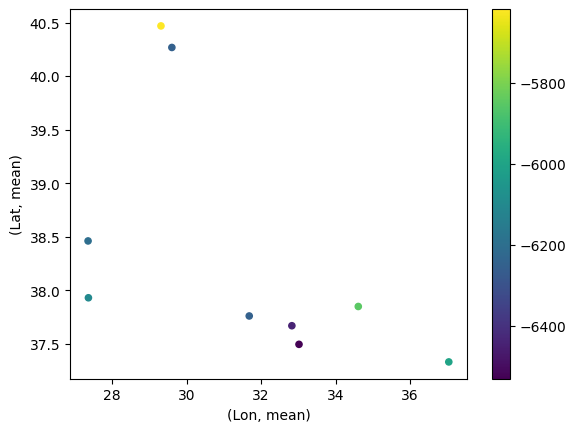

In [61]:
# Now let's plot the site locations and colour code them based on the mean date of the cow bones

final_df.plot.scatter(x=1, y=0, c=final_df['Date']['mean'], colormap='viridis')

# Note. Here x=1 means "Use the first column for x" (aka Longitute) and y=1 means "Use the 0th column for y" (ie Latitude)
# If we didn't have the "double header" format that comes from the aggregation of the dataframe we could have just done "x='Lon', y='Lat'"

If we superimpose this on a map of turkey (scaled to the same coordinates) we're starting to get somewhere!

<div>
<img src="Turkey.png" width="700"/>
</div>

# Exercises

### Exercise 1
Attempt the same thing with horses (Equidae). Note that there are again multiple labels in the Animal column for horses. Be sure to rename them all Equidae

In [ ]:
# To start, let's again identify the multiple labels

from collections import Counter
Counter(df_raw['Animal'].tolist())

### Exercise 2
We might want to see if these Neolithic cultures are treating animals differently. Look at the top 10 most common bones for cows, horses, and sheep/goats (including the "Ovis" entries - this is the genus name).

Are there any differences? How might you explain any differences?

### Exercise 3
We previously dropped the column "Has physiological sex determination [Source]" because it was 85.6% NaN values. But let's now rerun the cells without removing it and look only at the rows which have an entry (the rows which are NOT NaN - you can do this with the "dropna" method).

Here we have information on whether the animal was young or old, and male or female.

Tidy things up a bit by renaming some of the row labels using the dictionary provided in the next cell. Then again remove all NaN values with dropna. Now you only have 3 classes: Male, Female, and Young. Again study the cows, horses, and sheep/goats/ovis, but this time don't group by city (just consider all sites as one Neolithic culture). Do you notice any differences in sex/age distributions? What might this tell us?

If there are enough data for any of the sites (at least 100 rows), then look for differences at the site-level.